**You have done segmentation of EO images based on land-cover (man-made, forests, ocean). Take some patches of similar types of land-cover. Then, use PCA to reduce the dimension of the data into three so that you can visualise the data. Now, see if the data from the various land-covers cluster in PC-dimensions.**

I have chosen various types of land:
- forest
- urban
- sea
- desert

Each class behaves differently on 3-dimensional graph resulting from PCA analysis.
Forest, sea and desert scenes came out uniformly, they form seperate clusters with outliers present. However the urban samples are complete mess and they are spread out on the whole graph. I suspected it will be like this because pixels on urban scene tend to vary a lot, we have many materials, concrete, roads, parks, mixed pixels.

In [69]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

DATA = Path("./scenes")
S2_BANDS = ["B04", "B03", "B02"]
PATCH = 32
STRIDE = 4
LABELS = {"forest": 0, "urban": 1, "sea": 2, "desert": 3}


def get_raster_image(filename: str, data_dir: Path = DATA) -> np.ndarray:
    bands = []
    for band in S2_BANDS:
        with rasterio.open(data_dir / f"{filename}_{band}.tif") as src:
            bands.append(src.read(1).astype(np.float32) / 10000.0)
    return np.dstack(bands)


def to_rgb(image: np.ndarray, lower: int = 2, upper: int = 98, min_span: float = 0.08) -> np.ndarray:
    channels = []
    for i in range(image.shape[-1]):
        band = image[..., i]
        lo, hi = np.percentile(band, (lower, upper))
        if hi - lo < min_span:
            mid = 0.5 * (lo + hi)
            lo, hi = mid - min_span / 2, mid + min_span / 2
        channels.append(np.clip((band - lo) / (hi - lo + 1e-6), 0, 1))
    return np.dstack(channels).astype(np.float32)


def display_raster_image(
    first_image: np.ndarray,
    second_image: np.ndarray,
    first_title: str = "",
    second_title: str = "",
):
    _, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(to_rgb(first_image))
    ax[1].imshow(to_rgb(second_image))
    ax[0].set_title(first_title)
    ax[1].set_title(second_title)
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


def extract_patches(img: np.ndarray, patch: int = PATCH, stride: int = STRIDE) -> np.ndarray:
    H, W, _ = img.shape
    patches = [
        img[r : r + patch, c : c + patch]
        for r in range(0, H - patch + 1, stride)
        for c in range(0, W - patch + 1, stride)
    ]
    if not patches:
        raise ValueError(f"Image {img.shape} is smaller than patch {patch}")
    return np.stack(patches, axis=0)

forest: (392, 361, 3)
urban: (339, 363, 3)
ocean: (1307, 1004, 3)
desert: (690, 620, 3)


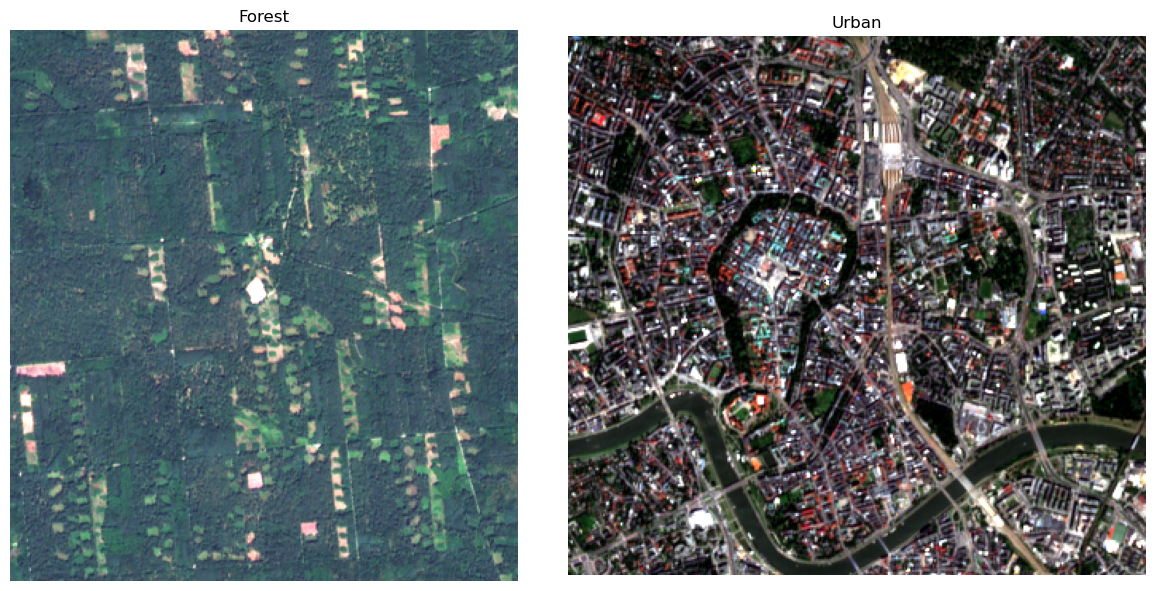

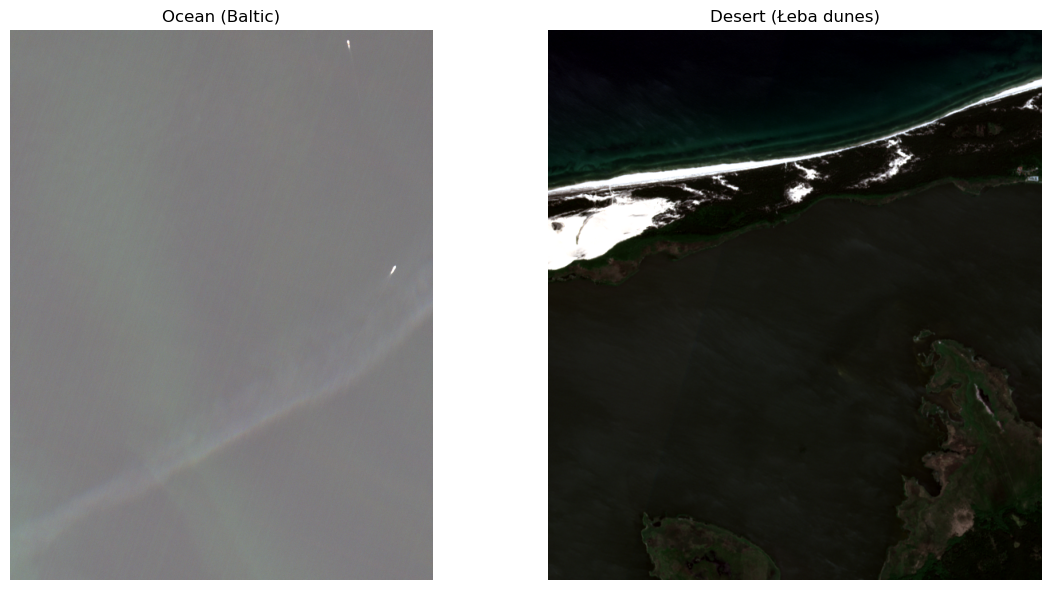

In [ ]:
forest = get_raster_image("s2_forest")
urban = get_raster_image("s2_urban")
sea = get_raster_image("s2_ocean")  # Baltic Sea crop
desert = get_raster_image("s2_desert")

print("forest:", forest.shape)
print("urban:", urban.shape)
print("sea:", sea.shape)
print("desert:", desert.shape)

display_raster_image(forest, urban, "Forest", "Urban")
display_raster_image(sea, desert, "Sea (Baltic)", "Desert (Łeba dunes)")

forest patches: (10, 32, 32, 3)
urban patches: (10, 32, 32, 3)
ocean patches: (10, 32, 32, 3)
desert patches: (10, 32, 32, 3)


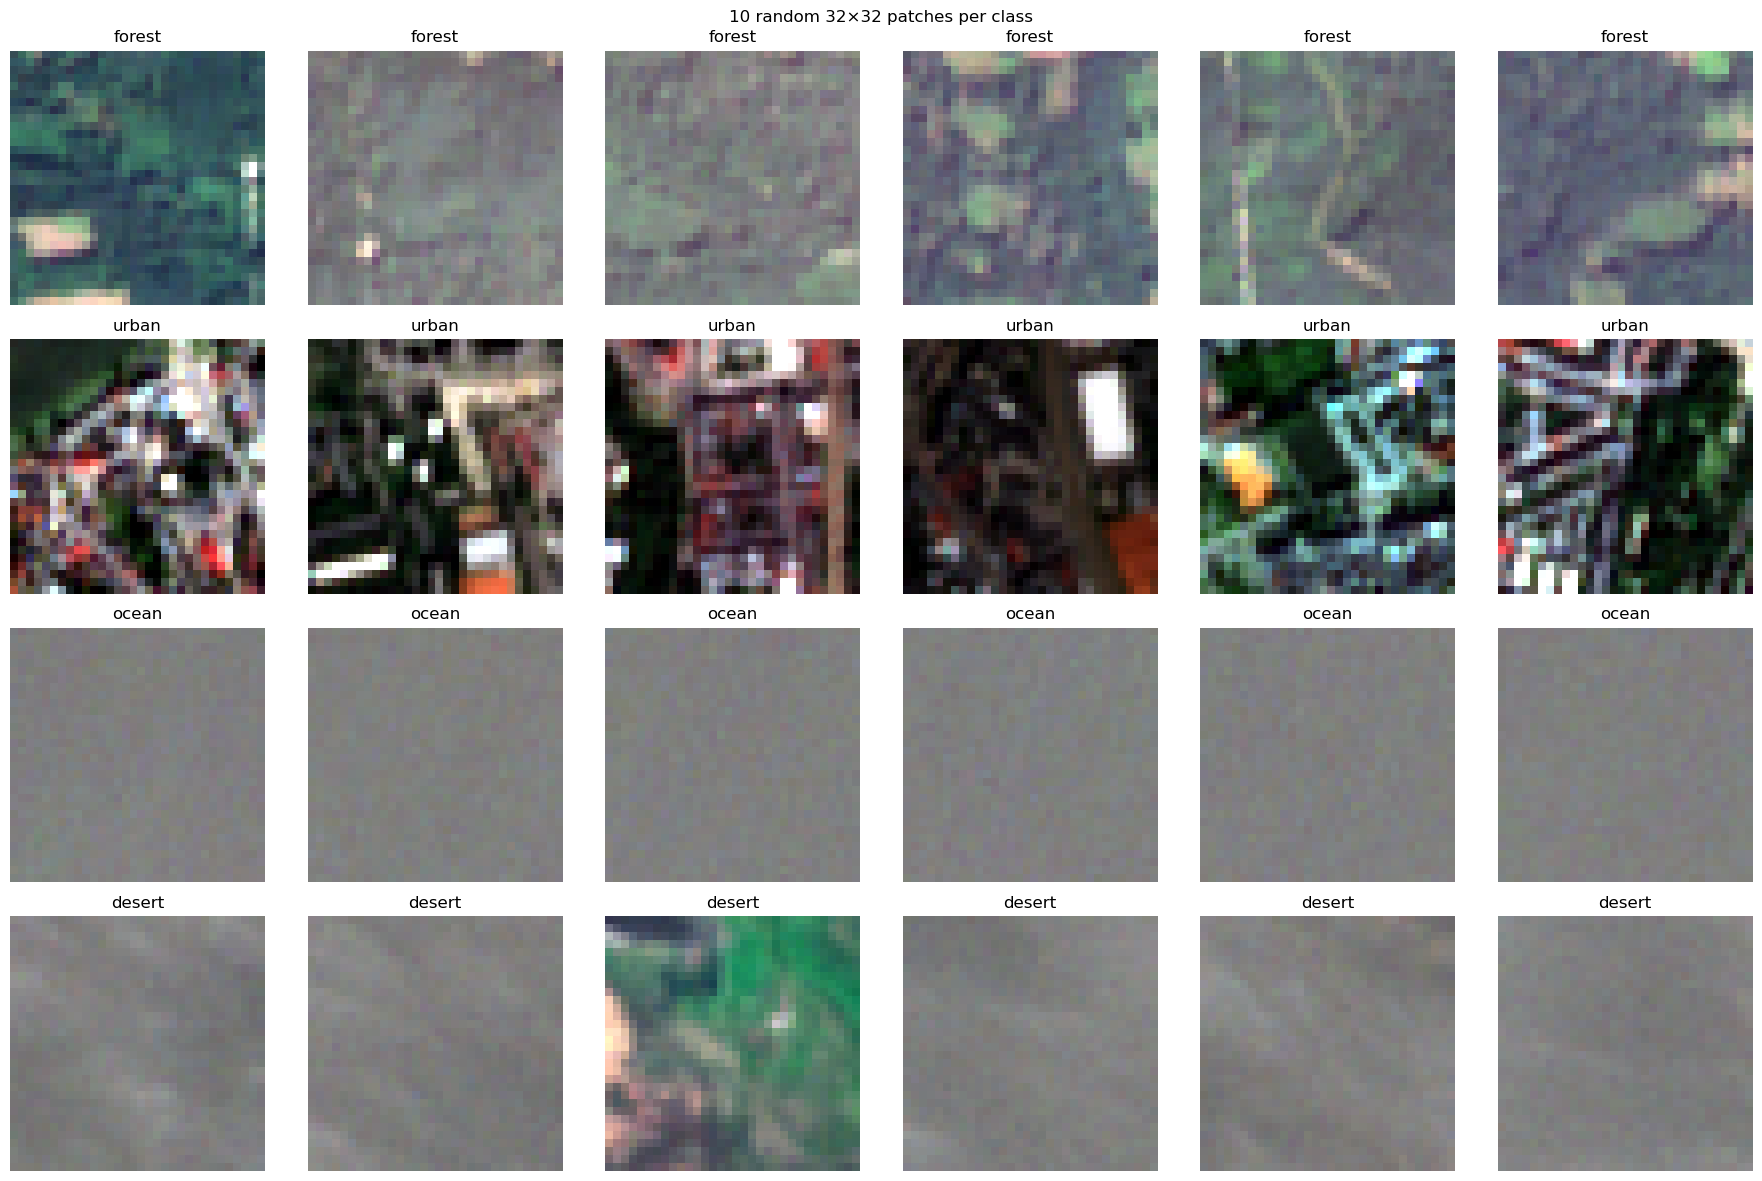

In [71]:
def sample_patches(patches: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    n = min(n, len(patches))
    return patches[rng.choice(len(patches), size=n, replace=False)]


N_PATCHES = 10
rng = np.random.default_rng(42)

X_forest = sample_patches(extract_patches(forest), N_PATCHES, rng)
X_urban = sample_patches(extract_patches(urban), N_PATCHES, rng)
X_sea = sample_patches(extract_patches(sea), N_PATCHES, rng)
X_desert = sample_patches(extract_patches(desert), N_PATCHES, rng)

print("forest patches:", X_forest.shape)
print("urban patches:", X_urban.shape)
print("sea patches:", X_sea.shape)
print("desert patches:", X_desert.shape)

n_show = min(6, N_PATCHES)
class_patches = [
    (X_forest, "forest"),
    (X_urban, "urban"),
    (X_sea, "sea"),
    (X_desert, "desert"),
]
fig, axes = plt.subplots(len(class_patches), n_show, figsize=(3 * n_show, 3 * len(class_patches)))
for i in range(n_show):
    for row, (patches, title) in enumerate(class_patches):
        axes[row, i].imshow(to_rgb(patches[i]))
        axes[row, i].set_title(title)
        axes[row, i].axis("off")
plt.suptitle(f"{N_PATCHES} random {PATCH}×{PATCH} patches per class")
plt.tight_layout()
plt.show()

In [72]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xf = X_forest.reshape(-1, 3)
Xu = X_urban.reshape(-1, 3)
Xs_sea = X_sea.reshape(-1, 3)
Xd = X_desert.reshape(-1, 3)
X = np.vstack([Xf, Xu, Xs_sea, Xd])

y = np.concatenate([
    np.full(len(Xf), LABELS["forest"]),
    np.full(len(Xu), LABELS["urban"]),
    np.full(len(Xs_sea), LABELS["sea"]),
    np.full(len(Xd), LABELS["desert"]),
])

Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=3)
pca_data = pca.fit_transform(Xs)

print("X:", X.shape, "y:", y.shape)
print("explained variance ratio:", pca.explained_variance_ratio_)
print("cumulative:", np.cumsum(pca.explained_variance_ratio_))

X: (40960, 3) y: (40960,)
explained variance ratio: [0.9644404  0.02434688 0.01121267]
cumulative: [0.9644404  0.9887873  0.99999994]


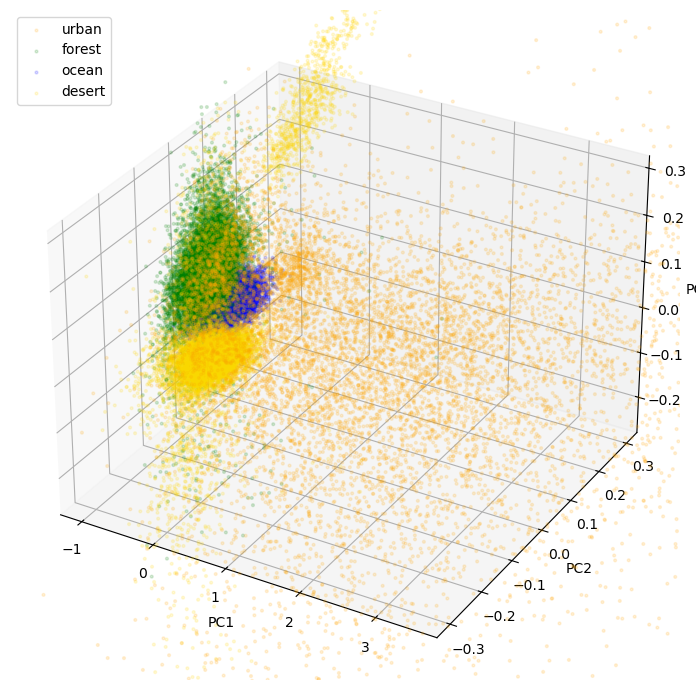

In [73]:
colors = {0: "green", 1: "orange", 2: "blue", 3: "gold"}
names = {0: "forest", 1: "urban", 2: "sea", 3: "desert"}

lo, hi = np.percentile(pca_data, [3, 97], axis=0)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for lab in (1, 0, 2, 3):
    m = y == lab
    ax.scatter(
        pca_data[m, 0], pca_data[m, 1], pca_data[m, 2],
        s=4, alpha=0.15, c=colors[lab], label=names[lab],
    )

ax.set_xlim(lo[0], hi[0])
ax.set_ylim(lo[1], hi[1])
ax.set_zlim(lo[2], hi[2])
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.tight_layout()
plt.show()